# RNN inicial y optimizada: comparación con SVM
## Demanda diaria de GROCERY I · Unidad 2

**Resultado buscado:** estimar las ventas de mañana de GROCERY I, sumadas entre las 54
tiendas, a partir de sus siete días anteriores. La respuesta está en **miles de unidades**.
Son ventas observadas como aproximación a la demanda; no se estima la demanda insatisfecha.
Una menor diferencia entre ventas reales y predicciones ayuda a evaluar la planificación
de inventario. No equivale a una recomendación de compra por tienda ni calcula ahorro monetario.

Este cuaderno complementa `Comparacion_SVM_GROCERY_I_MLflow.ipynb` y se ejecuta por separado.
Compara **SVR inicial, SVR optimizada, RNN inicial, RNN optimizada y persistencia**.
No cambia el cuaderno anterior ni sus resultados. Ejecutar todas las celdas en orden.

### 1. Entorno y reglas de comparación

Usar el kernel **Python (RNN demanda)** si está disponible. Para otro equipo, crear un
entorno Python 3.12 e instalar `requirements-rnn.txt`; no instalarlo sobre el entorno SVM.

| Elemento | SVM/SVR | RNN |
|---|---|---|
| Datos e información | 7 días × 5 variables | Los mismos 7 días × 5 variables |
| Entrada | 35 columnas | Secuencia de forma (7, 5) |
| Respuesta | Ventas del día siguiente | La misma respuesta |
| Prueba | Último 20% cronológico | Exactamente las mismas fechas |
| Selección | RMSE en 3 pliegues temporales | RMSE en los mismos 3 pliegues |

El modelo queda fijo en prueba y recibe el historial real actualizado cada día. No se
pronostican los 337 días desde una sola fecha. Los escaladores se ajustan únicamente con
entrenamiento; el escalado de la respuesta RNN se revierte antes de calcular los errores.

In [1]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import hashlib, importlib.metadata as metadata, json, sys, uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import mlflow
from mlflow.tracking import MlflowClient

candidatas = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "svm-demanda", Path.cwd() / "Repositorio TrABAJO U2" / "svm-demanda"]
BASE = next((p.resolve() for p in candidatas if (p / "rnn_demanda.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Abrir desde svm-demanda o desde el proyecto Aprendizaje automático.")
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import rnn_demanda as rnn
rnn.configurar_cpu()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
versiones = {p: metadata.version(p) for p in
    ["numpy", "pandas", "scikit-learn", "matplotlib", "mlflow", "keras"]}
versiones["tensorflow"] = rnn.tf.__version__
display(pd.Series(versiones, name="Versión").to_frame())
print("Python:", sys.executable)

Python: C:\Users\ASUS\Desktop\7mo Ciclo\Aprendizaje automático\Repositorio TrABAJO U2\svm-demanda\.venv-rnn\Scripts\python.exe


,Versión
numpy,1.26.4
pandas,2.3.3
scikit-learn,1.5.2
matplotlib,3.10.0
mlflow,3.18.0
keras,3.14.1
tensorflow,2.16.2


### 2. Mismos datos y preparación que la SVM

Se conserva GROCERY I, suma diaria / 1000 y redondeo a tres decimales. Los cuatro 25 de
diciembre ausentes se completan con cero, igual que en SVM; no demuestran ventas nulas.
La variable heredada `fecha_especial` usa fechas de 2019 y es constante en 2013–2017.
Se conserva para comparar el mismo experimento. No se añaden promociones ni petróleo.

In [2]:
FAMILIA, VENTANA, SEMILLA = "GROCERY I", 7, 42
VARIABLES_HISTORIA = ["demanda", "dia_semana", "mes", "es_fin_de_semana", "fecha_especial"]
FECHAS_ESPECIALES = ["2019-01-01", "2019-02-14"]
FRACCION_PRUEBA, N_PLIEGUES = 0.20, 3
PARAM_GRID = {"modelSVM__C": [0.1, 1.0, 10.0, 100.0],
    "modelSVM__kernel": ["linear", "poly", "rbf", "sigmoid"],
    "modelSVM__epsilon": [0.1], "modelSVM__gamma": ["scale"]}
rutas = [BASE / "data/raw/train.csv", *sorted(BASE.glob("store-sales-time-series-forecasting*/train.csv"))]
ARCHIVO_TRAIN = next((p for p in rutas if p.is_file()), None)
if ARCHIVO_TRAIN is None: raise FileNotFoundError("Falta train.csv del dataset Store Sales.")
GRUPO = datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:6]
SALIDA = BASE / "resultados_rnn" / GRUPO
SALIDA.mkdir(parents=True, exist_ok=True)
print("Resultados:", SALIDA)

Resultados: C:\Users\ASUS\Desktop\7mo Ciclo\Aprendizaje automático\Repositorio TrABAJO U2\svm-demanda\resultados_rnn\20261116_094510_6b01a9


In [3]:
bloques_familia = []
filas_csv = 0
for bloque in pd.read_csv(ARCHIVO_TRAIN,
                         usecols=["date", "store_nbr", "family", "sales"],
                         parse_dates=["date"], chunksize=200_000):
    filas_csv += len(bloque)
    bloques_familia.append(bloque.loc[bloque["family"].eq(FAMILIA)].copy())
ventas = pd.concat(bloques_familia, ignore_index=True)
del bloques_familia, bloque
if ventas.empty:
    raise ValueError(f"La familia {FAMILIA} no aparece en el CSV.")
if ventas[["date", "store_nbr", "sales"]].isna().any().any():
    raise ValueError("Hay datos nulos en las columnas necesarias.")
if ventas.duplicated(["date", "store_nbr", "family"]).any():
    raise ValueError("Hay registros duplicados de fecha, tienda y familia.")
if not np.isfinite(ventas["sales"]).all() or (ventas["sales"] < 0).any():
    raise ValueError("Las ventas contienen valores no finitos o negativos.")

serie = ventas.groupby("date")["sales"].sum().div(1000).round(3)
fechas = pd.date_range(serie.index.min(), serie.index.max(), freq="D")
fechas_ausentes = fechas.difference(serie.index)
diario = pd.DataFrame({"fecha": fechas, "producto": FAMILIA,
                       "demanda": serie.reindex(fechas, fill_value=0.0).to_numpy()})
diario["fecha_imputada"] = diario["fecha"].isin(fechas_ausentes)
display(pd.Series({"Filas del CSV": filas_csv, "Filas de GROCERY I": len(ventas),
    "Tiendas": ventas["store_nbr"].nunique(), "Días observados": len(serie),
    "Días del calendario completo": len(diario), "Días imputados con cero": len(fechas_ausentes),
    "Inicio": str(fechas.min().date()), "Fin": str(fechas.max().date())}, name="Valor").to_frame())
print("Fechas imputadas:", fechas_ausentes.strftime("%Y-%m-%d").tolist())
display(diario.head(8))
diario.to_csv(SALIDA / "demanda_diaria.csv", index=False)

Fechas imputadas: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


,Valor
Filas del CSV,3000888
Filas de GROCERY I,90936
Tiendas,54
Días observados,1684
Días del calendario completo,1688
Días imputados con cero,4
Inicio,2013-01-01
Fin,2017-08-15


,fecha,producto,demanda,fecha_imputada
0,2013-01-01,GROCERY I,0.700,False
1,2013-01-02,GROCERY I,202.020,False
2,2013-01-03,GROCERY I,144.878,False
3,2013-01-04,GROCERY I,135.754,False
4,2013-01-05,GROCERY I,188.356,False
5,2013-01-06,GROCERY I,207.297,False
6,2013-01-07,GROCERY I,133.189,False
7,2013-01-08,GROCERY I,133.290,False


### 3. Convertir las columnas en secuencias y separar por fecha

La primera fila usa del 1 al 7 de enero para predecir el 8 de enero. El orden es siempre
del día más antiguo al más reciente. La demanda del día objetivo nunca forma parte de X.
Las ventanas de validación pueden usar ventas reales anteriores: es el mismo protocolo
diario de SVM. Las tres validaciones externas quedan dentro del 80% de entrenamiento.

In [4]:
diario["dia_semana"] = diario["fecha"].dt.dayofweek
diario["mes"] = diario["fecha"].dt.month
diario["es_fin_de_semana"] = (diario["dia_semana"] >= 5).astype(int)
diario["fecha_especial"] = diario["fecha"].isin(pd.to_datetime(FECHAS_ESPECIALES)).astype(int)
tabla = diario.copy()
columnas = []
for retraso in range(VENTANA, 0, -1):
    for variable in VARIABLES_HISTORIA:
        nombre = f"{variable}_lag{retraso}"
        tabla[nombre] = tabla.groupby("producto")[variable].shift(retraso)
        columnas.append(nombre)
tabla = tabla.dropna(subset=columnas).sort_values("fecha").reset_index(drop=True)
assert len(columnas) == VENTANA * len(VARIABLES_HISTORIA)
assert not tabla[columnas].isna().any().any()
assert np.isfinite(tabla[columnas].to_numpy()).all()
np.testing.assert_allclose(tabla["demanda_lag1"], diario["demanda"].shift(1).iloc[VENTANA:])
print("Filas utilizables:", len(tabla), "| variables:", len(columnas))
display(tabla[["fecha", "demanda_lag7", "demanda_lag2", "demanda_lag1", "demanda"]].head())

Filas utilizables: 1681 | variables: 35


,fecha,demanda_lag7,demanda_lag2,demanda_lag1,demanda
0,2013-01-08,0.700,207.297,133.189,133.290
1,2013-01-09,202.020,133.189,133.290,115.871
2,2013-01-10,144.878,133.290,115.871,96.200
3,2013-01-11,135.754,115.871,96.200,103.280
4,2013-01-12,188.356,96.200,103.280,151.025


In [5]:
corte = int(len(tabla) * (1 - FRACCION_PRUEBA))
entrenamiento = tabla.iloc[:corte].reset_index(drop=True)
prueba = tabla.iloc[corte:].reset_index(drop=True)
X_train, y_train = entrenamiento[columnas], entrenamiento["demanda"]
X_test, y_test = prueba[columnas], prueba["demanda"]
fecha_prueba = prueba["fecha"].min()
pliegues = list(TimeSeriesSplit(n_splits=N_PLIEGUES, gap=0).split(X_train))
assert entrenamiento["fecha"].max() < fecha_prueba
assert (tabla["fecha"].diff().dropna() == pd.Timedelta(days=1)).all()
filas_particion = []
for i, (it, iv) in enumerate(pliegues, start=1):
    assert entrenamiento.loc[it, "fecha"].max() < entrenamiento.loc[iv, "fecha"].min()
    filas_particion.append({"Pliegue": i, "n_train": len(it), "n_validacion": len(iv),
        "Train desde": entrenamiento.loc[it, "fecha"].min().date(),
        "Train hasta": entrenamiento.loc[it, "fecha"].max().date(),
        "Validación desde": entrenamiento.loc[iv, "fecha"].min().date(),
        "Validación hasta": entrenamiento.loc[iv, "fecha"].max().date()})
particiones = pd.DataFrame(filas_particion)
print(f"Entrenamiento: {len(X_train)} días | Prueba: {len(X_test)} días desde {fecha_prueba.date()}")
display(particiones)
constantes = X_train.columns[X_train.nunique().eq(1)].tolist()
print("Variables constantes en entrenamiento:", constantes)
particiones.to_csv(SALIDA / "pliegues_temporales.csv", index=False)

X_secuencias = tabla[columnas].to_numpy(dtype="float32").reshape(-1, VENTANA, len(VARIABLES_HISTORIA))
Xr_train, Xr_test = X_secuencias[:corte], X_secuencias[corte:]
yr_train = y_train.to_numpy(dtype="float64")
np.testing.assert_allclose(Xr_train.reshape(len(X_train), -1), X_train.to_numpy(), rtol=1e-6)
np.testing.assert_allclose(Xr_test[:, -1, 0], X_test["demanda_lag1"], rtol=1e-6)
print("SVM:", X_train.shape, "| RNN:", Xr_train.shape, "| Test RNN:", Xr_test.shape)
display(pd.DataFrame(Xr_train[0], columns=VARIABLES_HISTORIA,
    index=[f"t-{i}" for i in range(7, 0, -1)]))

Entrenamiento: 1344 días | Prueba: 337 días desde 2016-09-13
Variables constantes en entrenamiento: ['fecha_especial_lag7', 'fecha_especial_lag6', 'fecha_especial_lag5', 'fecha_especial_lag4', 'fecha_especial_lag3', 'fecha_especial_lag2', 'fecha_especial_lag1']
SVM: (1344, 35) | RNN: (1344, 7, 5) | Test RNN: (337, 7, 5)


,Pliegue,n_train,n_validacion,Train desde,Train hasta,Validación desde,Validación hasta
0,1,336,336,2013-01-08,2013-12-09,2013-12-10,2014-11-10
1,2,672,336,2013-01-08,2014-11-10,2014-11-11,2015-10-12
2,3,1008,336,2013-01-08,2015-10-12,2015-10-13,2016-09-12


,demanda,dia_semana,mes,es_fin_de_semana,fecha_especial
t-7,0.700000,1.0,1.0,0.0,0.0
t-6,202.020004,2.0,1.0,0.0,0.0
t-5,144.878006,3.0,1.0,0.0,0.0
t-4,135.753998,4.0,1.0,0.0,0.0
t-3,188.356003,5.0,1.0,1.0,0.0
t-2,207.296997,6.0,1.0,1.0,0.0
t-1,133.188995,0.0,1.0,0.0,0.0


### 4. Recalcular las dos SVM de referencia

Se repite la misma búsqueda de 16 combinaciones, escalador y tres pliegues del cuaderno
anterior. Así este cuaderno es independiente y no mezcla predicciones de otras ejecuciones.
La selección usa validación; todavía no se calculan errores de prueba.

In [6]:
def crear_svr():
    return Pipeline([("scaler", StandardScaler()), ("modelSVM", SVR())])
tic = perf_counter()
svr_inicial = crear_svr().fit(X_train, y_train)
tiempo_svr_inicial = perf_counter() - tic
busqueda_svr = GridSearchCV(crear_svr(), PARAM_GRID, cv=pliegues,
    scoring="neg_root_mean_squared_error", n_jobs=1, error_score="raise", refit=True)
tic = perf_counter()
busqueda_svr.fit(X_train, y_train)
tiempo_svr_busqueda = perf_counter() - tic
svr_optimizada = busqueda_svr.best_estimator_
cv_svr = pd.DataFrame(busqueda_svr.cv_results_)
cv_svr["RMSE_CV"] = -cv_svr["mean_test_score"]
cv_svr.to_csv(SALIDA / "busqueda_svr.csv", index=False)
print("SVR seleccionada:", busqueda_svr.best_params_)
print("RMSE de validación:", -busqueda_svr.best_score_)

SVR seleccionada: {'modelSVM__C': 1.0, 'modelSVM__epsilon': 0.1, 'modelSVM__gamma': 'scale', 'modelSVM__kernel': 'linear'}
RMSE de validación: 34.578154280139664


### 5. RNN inicial y búsqueda temporal

Se usa una **RNN simple** (`SimpleRNN` con tanh y salida lineal), no una LSTM. La configuración
inicial tiene 16 neuronas y tasa de aprendizaje 0.001. Se comparan 4 configuraciones:
16/32 neuronas × tasa 0.001/0.003. La inicial está incluida en la búsqueda.

En cada pliegue externo, el último 20% de su entrenamiento se reserva **internamente**
para elegir épocas con EarlyStopping (máximo 80, paciencia 10). Luego se reajusta la red
en todo ese entrenamiento y se evalúa en la validación externa, aún no vista.
La ganadora minimiza el RMSE externo promedio. Para el entrenamiento final se usa la
mediana de las épocas elegidas en esos tres pliegues. Ni las épocas ni los hiperparámetros
se eligen con prueba. La implementación repetitiva está en `rnn_demanda.py`.

Las búsquedas tienen presupuestos distintos: 16 configuraciones SVR y 4 RNN. Los resultados
comparan estos procedimientos concretos, no prueban superioridad universal de una familia.

In [7]:
CANDIDATOS = list(ParameterGrid({"unidades": [16, 32], "learning_rate": [0.001, 0.003]}))
INDICE_INICIAL = CANDIDATOS.index({"unidades": 16, "learning_rate": 0.001})
resumen_rnn, detalle_rnn, curvas_rnn, INDICE_GANADOR, tiempo_rnn_busqueda = rnn.buscar_rnn(
    Xr_train, yr_train, pliegues, CANDIDATOS, semilla=SEMILLA, max_epocas=80, paciencia=10)
resumen_rnn.to_csv(SALIDA / "busqueda_rnn.csv")
detalle_rnn.to_csv(SALIDA / "pliegues_rnn.csv", index=False)
for (candidato, pliegue), curva in curvas_rnn.items():
    curva.to_csv(SALIDA / f"curva_candidato_{candidato}_pliegue_{pliegue}.csv")
display(resumen_rnn.sort_values("RMSE_CV").round(4))
print("RNN seleccionada por validación:", CANDIDATOS[INDICE_GANADOR])
if INDICE_GANADOR == INDICE_INICIAL:
    display(Markdown("**La búsqueda conservó la configuración inicial de RNN.** "
        "Con la misma semilla y épocas, ambas RNN producirán las mismas predicciones. "
        "Esto significa que esta búsqueda no encontró una configuración mejor."))

RNN 1/4 | pliegue 1/3 | épocas=80 | RMSE=29.063
RNN 1/4 | pliegue 2/3 | épocas=41 | RMSE=32.950
RNN 1/4 | pliegue 3/3 | épocas=53 | RMSE=44.039
RNN 2/4 | pliegue 1/3 | épocas=74 | RMSE=29.975
RNN 2/4 | pliegue 2/3 | épocas=12 | RMSE=33.570
RNN 2/4 | pliegue 3/3 | épocas=23 | RMSE=43.548
RNN 3/4 | pliegue 1/3 | épocas=66 | RMSE=30.704
RNN 3/4 | pliegue 2/3 | épocas=20 | RMSE=32.668
RNN 3/4 | pliegue 3/3 | épocas=21 | RMSE=44.013
RNN 4/4 | pliegue 1/3 | épocas=20 | RMSE=29.296
RNN 4/4 | pliegue 2/3 | épocas=8 | RMSE=33.354
RNN 4/4 | pliegue 3/3 | épocas=13 | RMSE=44.192
RNN seleccionada por validación: {'learning_rate': 0.001, 'unidades': 16}


,RMSE_CV,std_CV,epocas,segundos_busqueda,learning_rate,unidades
candidato,,,,,,
0,35.3509,7.7711,53,36.5429,0.001,16.0
3,35.6140,7.7004,13,18.1929,0.003,32.0
1,35.6976,7.0321,23,20.1114,0.001,32.0
2,35.7949,7.1842,21,24.1020,0.003,16.0


**La búsqueda conservó la configuración inicial de RNN.** Con la misma semilla y épocas, ambas RNN producirán las mismas predicciones. Esto significa que esta búsqueda no encontró una configuración mejor.

### 6. Reentrenar las dos RNN y visualizar su aprendizaje

Ambas redes vuelven a entrenarse con los 1344 días de entrenamiento completos y su
número fijo de épocas. Se escala también y para estabilizar el aprendizaje, y se devuelve
a miles de unidades al predecir. La curva mostrada pertenece al último pliegue de validación
interna de la configuración ganadora; no representa el desempeño en prueba.

RNN inicial | {'learning_rate': 0.001, 'unidades': 16} | épocas: 53
RNN optimizada | {'learning_rate': 0.001, 'unidades': 16} | épocas: 53
Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ memoria_recurrente (SimpleRNN)  │ (None, 16)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ demanda_escalada (Dense)        │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 1,109 (4.34 KB)
 Trainable params: 369 (1.44 KB)
 Non-trainable params: 0 (0.00 B)
 Optimizer params: 740 (2.89 KB)


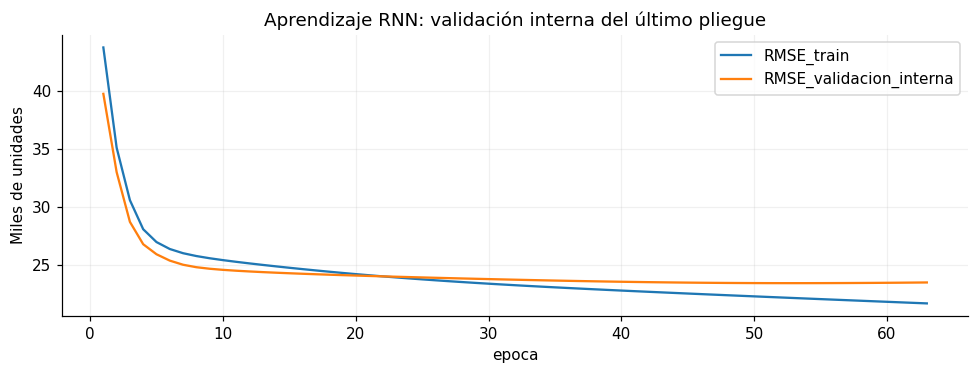

In [8]:
redes = {}
for nombre, indice in [("RNN inicial", INDICE_INICIAL), ("RNN optimizada", INDICE_GANADOR)]:
    redes[nombre] = rnn.entrenar_final(Xr_train, yr_train, CANDIDATOS[indice],
        epocas=int(resumen_rnn.loc[indice, "epocas"]), semilla=SEMILLA)
    print(nombre, "|", CANDIDATOS[indice], "| épocas:", redes[nombre]["epocas"])
redes["RNN optimizada"]["modelo"].summary()
curva = curvas_rnn[(INDICE_GANADOR, N_PLIEGUES)]
fig, ax = plt.subplots(figsize=(9, 3.5))
curva[["RMSE_train", "RMSE_validacion_interna"]].plot(ax=ax)
ax.set(title="Aprendizaje RNN: validación interna del último pliegue", ylabel="Miles de unidades")
fig.tight_layout(); fig.savefig(SALIDA / "aprendizaje_rnn.png", dpi=150)
plt.show(); plt.close(fig)

### 7. Evaluación final: las mismas fechas y unidades

Menor MAE = menor error absoluto promedio. RMSE penaliza más los errores grandes.
R² mide ajuste y puede ser negativo. Se muestran todos los días y, por separado,
solo días con ventas observadas para transparentar el efecto de los ceros imputados.
No se recortan valores negativos ni se modifican predicciones después de ver la prueba.

In [9]:
def metricas(real, pred):
    return {"MAE": float(mean_absolute_error(real, pred)),
        "RMSE": float(np.sqrt(mean_squared_error(real, pred))), "R2": float(r2_score(real, pred))}
predicciones = prueba[["fecha", "demanda", "fecha_imputada"]].copy()
predicciones["SVR inicial"] = svr_inicial.predict(X_test)
predicciones["SVR optimizada"] = svr_optimizada.predict(X_test)
for nombre, paquete in redes.items(): predicciones[nombre] = rnn.predecir(paquete, Xr_test)
predicciones["Persistencia"] = X_test["demanda_lag1"].to_numpy()
NOMBRES = ["SVR inicial", "SVR optimizada", "RNN inicial", "RNN optimizada", "Persistencia"]
comparacion = pd.DataFrame({n: metricas(y_test, predicciones[n]) for n in NOMBRES}).T
comparacion.index.name = "Modelo"
comparacion["segundos_ajuste"] = [tiempo_svr_inicial, busqueda_svr.refit_time_,
    redes["RNN inicial"]["segundos_ajuste"], redes["RNN optimizada"]["segundos_ajuste"], 0.0]
comparacion["segundos_busqueda"] = [0.0, tiempo_svr_busqueda,
    float(resumen_rnn.loc[INDICE_INICIAL, "segundos_busqueda"]), tiempo_rnn_busqueda, 0.0]
# La búsqueda completa incluye el coste de validación de la inicial; estos tiempos no se suman.
observadas = ~predicciones["fecha_imputada"]
solo_observadas = pd.DataFrame({n: metricas(y_test[observadas],
    predicciones.loc[observadas, n]) for n in NOMBRES}).T
comparacion.to_csv(SALIDA / "comparacion.csv")
solo_observadas.to_csv(SALIDA / "comparacion_solo_observados.csv")
predicciones.to_csv(SALIDA / "predicciones.csv", index=False)
display(comparacion.round(4))
print(f"Sensibilidad: {observadas.sum()} días observados de {len(prueba)}")
display(solo_observadas.round(4))
assert np.isfinite(predicciones[NOMBRES].to_numpy()).all()
referencia = BASE / "resultados/comparacion.csv"
if referencia.is_file():
    anterior = pd.read_csv(referencia, index_col="Modelo")
    display(comparacion.loc[["SVR inicial", "SVR optimizada"], ["MAE", "RMSE"]].join(
        anterior[["MAE", "RMSE"]], lsuffix="_actual", rsuffix="_original").round(4))

Sensibilidad: 336 días observados de 337


,MAE,RMSE,R2,segundos_ajuste,segundos_busqueda
Modelo,,,,,
SVR inicial,47.9854,66.4525,-0.1733,0.1114,0.0000
SVR optimizada,24.7379,46.9256,0.4150,0.1229,4.9358
RNN inicial,23.4749,43.4482,0.4984,7.7870,36.5429
RNN optimizada,23.4749,43.4482,0.4984,7.5107,98.9713
Persistencia,45.9650,67.2776,-0.2026,0.0000,0.0000


,MAE,RMSE,R2
SVR inicial,47.5328,65.6503,-0.2017
SVR optimizada,23.5547,40.9607,0.5322
RNN inicial,22.5377,39.4030,0.5671
RNN optimizada,22.5377,39.4030,0.5671
Persistencia,44.8721,63.4955,-0.1241


,MAE_actual,RMSE_actual,MAE_original,RMSE_original
Modelo,,,,
SVR inicial,47.9854,66.4525,47.9854,66.4525
SVR optimizada,24.7379,46.9256,24.7379,46.9256


### 8. Comparación visual para presentar al cliente

La vista usa **todos los días de prueba** en las métricas y los últimos 60 en el acercamiento.
La tabla de siete días es el final del período de prueba, no una semana futura pronosticada
desde hoy. El error con signo indica sobreestimación (+) o subestimación (−).

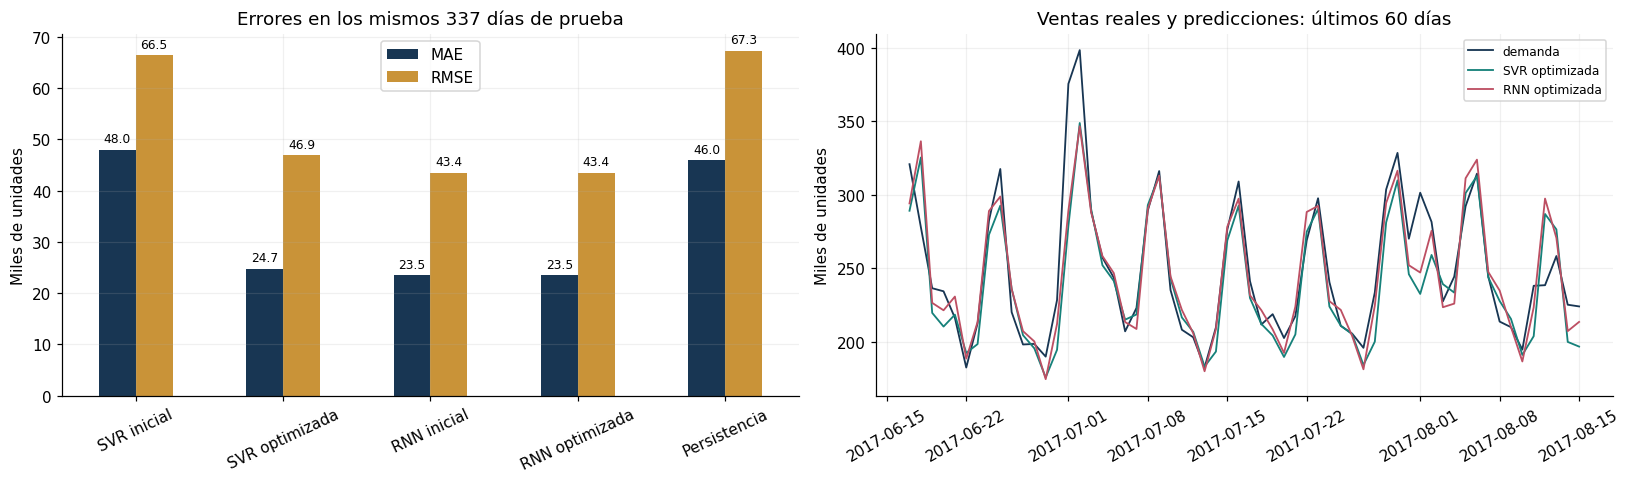

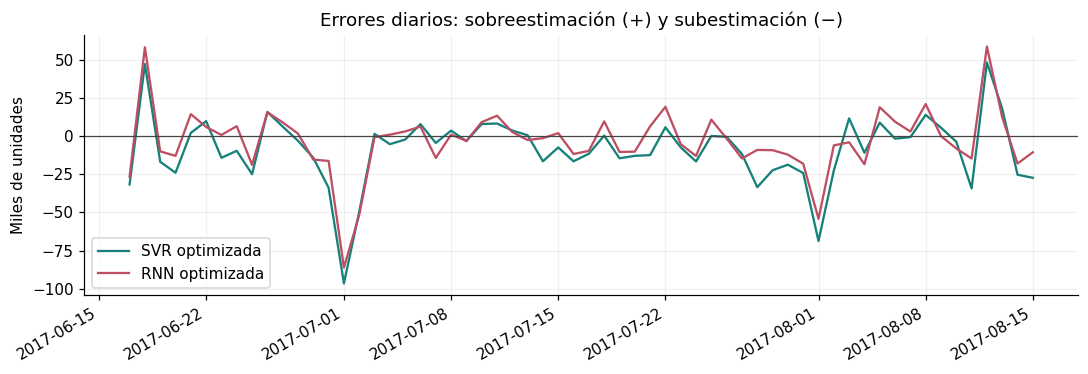

,fecha,demanda,SVR optimizada,RNN optimizada,Error absoluto SVR optimizada,Error absoluto RNN optimizada
330,2017-08-09,210.098,215.688,210.179993,5.590,0.082
331,2017-08-10,194.854,191.228,186.809998,3.626,8.044
332,2017-08-11,238.222,203.979,223.595001,34.243,14.627
333,2017-08-12,238.628,287.016,297.468994,48.388,58.841
334,2017-08-13,258.442,276.515,270.773010,18.073,12.331
335,2017-08-14,225.356,200.094,207.436996,25.262,17.919
336,2017-08-15,224.208,196.922,213.677994,27.286,10.530


In [10]:
COLORES = {"demanda": "#183653", "SVR inicial": "#c99338", "SVR optimizada": "#16817a",
    "RNN inicial": "#9a7ac0", "RNN optimizada": "#bd4f63", "Persistencia": "#808080"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
comparacion[["MAE", "RMSE"]].plot.bar(ax=axes[0], color=["#183653", "#c99338"], rot=25)
for contenedor in axes[0].containers: axes[0].bar_label(contenedor, fmt="%.1f", fontsize=8, padding=3)
axes[0].set(title="Errores en los mismos 337 días de prueba", ylabel="Miles de unidades", xlabel="")
vista = predicciones.tail(60)
for nombre in ["demanda", "SVR optimizada", "RNN optimizada"]:
    axes[1].plot(vista["fecha"], vista[nombre], label=nombre, color=COLORES[nombre], lw=1.2)
axes[1].set(title="Ventas reales y predicciones: últimos 60 días", ylabel="Miles de unidades")
axes[1].tick_params(axis="x", rotation=30); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(SALIDA / "comparacion_cliente.png", dpi=170, bbox_inches="tight")
plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(10, 3.5))
for nombre in ["SVR optimizada", "RNN optimizada"]:
    ax.plot(vista["fecha"], vista[nombre] - vista["demanda"], label=nombre, color=COLORES[nombre])
ax.axhline(0, color="#444444", lw=0.8)
ax.set(title="Errores diarios: sobreestimación (+) y subestimación (−)", ylabel="Miles de unidades")
ax.legend(); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(SALIDA / "errores_diarios.png", dpi=150); plt.show(); plt.close(fig)
casos_cliente = predicciones.tail(7)[["fecha", "demanda", "SVR optimizada", "RNN optimizada"]].copy()
for n in ["SVR optimizada", "RNN optimizada"]:
    casos_cliente[f"Error absoluto {n}"] = abs(casos_cliente[n] - casos_cliente["demanda"])
display(casos_cliente.round(3))
casos_cliente.to_csv(SALIDA / "casos_cliente_7_dias.csv", index=False)

### 9. Guardar y recuperar los modelos

Las RNN se conservan como `.keras` junto con sus **dos escaladores**. Guardar solo los pesos
no basta para reproducir una predicción. Se verifica la recuperación sobre toda la prueba.
Los pipelines SVR se guardan completos. Cargar únicamente archivos propios y de confianza.

In [11]:
import joblib
for nombre, paquete in redes.items():
    carpeta = SALIDA / nombre.lower().replace(" ", "_")
    rnn.guardar(paquete, carpeta)
    recuperado = rnn.cargar(carpeta)
    np.testing.assert_allclose(rnn.predecir(recuperado, Xr_test), predicciones[nombre], rtol=1e-6, atol=1e-4)
for nombre, modelo in [("SVR inicial", svr_inicial), ("SVR optimizada", svr_optimizada)]:
    ruta = SALIDA / (nombre.lower().replace(" ", "_") + ".joblib")
    joblib.dump(modelo, ruta)
    np.testing.assert_allclose(joblib.load(ruta).predict(X_test), predicciones[nombre])
huella = hashlib.sha256()
with ARCHIVO_TRAIN.open("rb") as archivo:
    for bloque in iter(lambda: archivo.read(1024 * 1024), b""): huella.update(bloque)
metadatos = {"grupo": GRUPO, "sha256_train": huella.hexdigest(), "familia": FAMILIA,
    "unidad": "miles_de_unidades", "protocolo": "un_paso_diario_con_historia_observada",
    "variables": VARIABLES_HISTORIA, "columnas": columnas, "ventana": VENTANA,
    "n_train": len(X_train), "n_test": len(X_test), "semilla": SEMILLA,
    "inicio_test": str(prueba.fecha.min().date()), "fin_test": str(prueba.fecha.max().date()),
    "rnn_candidatos": CANDIDATOS, "rnn_ganador": INDICE_GANADOR,
    "svr_ganador": busqueda_svr.best_params_, "versiones": versiones,
    "epocas_rnn": {n: p["epocas"] for n, p in redes.items()},
    "fuentes_codigo": ["rnn_demanda.py", "Comparacion_RNN_vs_SVM_GROCERY_I_MLflow.ipynb"]}
(SALIDA / "metadatos.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8")
print("Recuperación verificada: las cuatro predicciones coinciden en toda la prueba.")

Recuperación verificada: las cuatro predicciones coinciden en toda la prueba.


### 10. Conclusión calculada a partir de los resultados

La conclusión se genera con los errores obtenidos, incluso si la RNN no supera a SVM.
La prueba sirve para informar desempeño final, no para volver a ajustar candidatos.
Una única semilla no mide toda la variabilidad del entrenamiento de una red.

In [12]:
rmse_svr = comparacion.loc["SVR optimizada", "RMSE"]
rmse_rnn = comparacion.loc["RNN optimizada", "RMSE"]
reduccion = 100 * (rmse_svr - rmse_rnn) / rmse_svr
ganador_prueba = "RNN optimizada" if rmse_rnn < rmse_svr else "SVR optimizada"
conclusion = (
    f"Se predijeron las ventas diarias agregadas de **{FAMILIA}** con siete días de historia. "
    f"En las mismas **{len(prueba)} fechas de prueba**, la SVR optimizada obtuvo MAE "
    f"**{comparacion.loc['SVR optimizada', 'MAE']:.2f}** y RMSE **{rmse_svr:.2f}**; "
    f"la RNN optimizada obtuvo MAE **{comparacion.loc['RNN optimizada', 'MAE']:.2f}** "
    f"y RMSE **{rmse_rnn:.2f} miles de unidades**. La reducción de RMSE de RNN frente a SVR "
    f"fue **{reduccion:.2f}%** (negativo indica empeoramiento). Entre ambas, "
    f"**{ganador_prueba}** tuvo menor RMSE en esta prueba. "
    f"La persistencia obtuvo RMSE **{comparacion.loc['Persistencia', 'RMSE']:.2f}**. "
    "La optimización se eligió con validación temporal y la prueba se reservó para informar resultados. "
    "Esto evalúa un día con historia real disponible, no varios meses desde una sola fecha. "
    "Los errores se refieren a miles de unidades: MAE 25 equivale a unas 25 000 unidades diarias. "
    "No se han calculado costes, ahorro monetario ni intervalos de incertidumbre.")
if INDICE_GANADOR == INDICE_INICIAL:
    conclusion += (" La búsqueda RNN conservó la configuración inicial; por ello, "
        "RNN inicial y optimizada coinciden. No se obtuvo una mejora al ajustar sus hiperparámetros.")
display(Markdown(conclusion))
(SALIDA / "conclusion.md").write_text(conclusion, encoding="utf-8")

Se predijeron las ventas diarias agregadas de **GROCERY I** con siete días de historia. En las mismas **337 fechas de prueba**, la SVR optimizada obtuvo MAE **24.74** y RMSE **46.93**; la RNN optimizada obtuvo MAE **23.47** y RMSE **43.45 miles de unidades**. La reducción de RMSE de RNN frente a SVR fue **7.41%** (negativo indica empeoramiento). Entre ambas, **RNN optimizada** tuvo menor RMSE en esta prueba. La persistencia obtuvo RMSE **67.28**. La optimización se eligió con validación temporal y la prueba se reservó para informar resultados. Esto evalúa un día con historia real disponible, no varios meses desde una sola fecha. Los errores se refieren a miles de unidades: MAE 25 equivale a unas 25 000 unidades diarias. No se han calculado costes, ahorro monetario ni intervalos de incertidumbre. La búsqueda RNN conservó la configuración inicial; por ello, RNN inicial y optimizada coinciden. No se obtuvo una mejora al ajustar sus hiperparámetros.

### 11. MLflow local: cuatro modelos y candidatos RNN

Se usa la misma base local `mlflow_cuaderno.db` y un **nuevo experimento** para comparar
las cuatro ejecuciones. No se inicia otro servidor automáticamente. Las RNN se guardan
como artefactos `.keras` + escaladores, no como un endpoint de predicción MLflow.
La persistencia queda en las tablas y como métrica de referencia; no tiene entrenamiento.

In [13]:
REGISTRAR_MLFLOW = True
if REGISTRAR_MLFLOW:
    TRACKING_URI = "sqlite:///" + (BASE / "mlflow_cuaderno.db").as_posix()
    mlflow.set_tracking_uri(TRACKING_URI)
    if mlflow.active_run() is not None: raise RuntimeError("Finaliza la ejecución MLflow activa.")
    cliente = MlflowClient(tracking_uri=TRACKING_URI)
    EXPERIMENTO = "Comparacion_SVR_RNN_GROCERY_I"
    experimento = cliente.get_experiment_by_name(EXPERIMENTO)
    eid = (experimento.experiment_id if experimento is not None else
        cliente.create_experiment(EXPERIMENTO, artifact_location=(BASE / "mlartifacts_cuaderno").as_uri()))
    mlflow.set_experiment(experiment_id=eid)
    cv_inicial = float(cv_svr.loc[cv_svr["param_modelSVM__C"].eq(1.0) &
        cv_svr["param_modelSVM__kernel"].eq("rbf"), "RMSE_CV"].iloc[0])
    cv_por_modelo = {"SVR inicial": cv_inicial, "SVR optimizada": -busqueda_svr.best_score_,
        "RNN inicial": resumen_rnn.loc[INDICE_INICIAL, "RMSE_CV"],
        "RNN optimizada": resumen_rnn.loc[INDICE_GANADOR, "RMSE_CV"]}
    run_ids = {}
    for nombre in NOMBRES[:-1]:
        with mlflow.start_run(run_name=nombre) as run:
            run_ids[nombre] = run.info.run_id
            mlflow.set_tags({"comparacion": GRUPO, "tipo": "modelo_principal", "familia": FAMILIA,
                "protocolo": "un_paso_diario", "sha256_train": huella.hexdigest()})
            parametros = ({**redes[nombre]["parametros"], "epocas": redes[nombre]["epocas"]}
                if nombre.startswith("RNN") else (svr_inicial if nombre == "SVR inicial"
                else svr_optimizada).named_steps["modelSVM"].get_params())
            mlflow.log_params({**parametros, "ventana": VENTANA, "n_train": len(X_train),
                "n_test": len(X_test), "semilla": SEMILLA, "unidad": "miles_de_unidades"})
            mlflow.log_metrics({"test_mae": comparacion.loc[nombre, "MAE"],
                "test_rmse": comparacion.loc[nombre, "RMSE"], "test_r2": comparacion.loc[nombre, "R2"],
                "cv_rmse": float(cv_por_modelo[nombre]),
                "test_rmse_solo_observados": solo_observadas.loc[nombre, "RMSE"],
                "segundos_ajuste": comparacion.loc[nombre, "segundos_ajuste"],
                "segundos_busqueda": comparacion.loc[nombre, "segundos_busqueda"],
                "persistencia_test_rmse": comparacion.loc["Persistencia", "RMSE"]})
            for ruta in SALIDA.iterdir():
                if ruta.is_file() and ruta.suffix != ".joblib": mlflow.log_artifact(str(ruta), "resultados")
            mlflow.log_artifact(str(BASE / "rnn_demanda.py"), "codigo")
            if nombre.startswith("RNN"):
                mlflow.log_artifacts(str(SALIDA / nombre.lower().replace(" ", "_")), "modelo")
            else:
                mlflow.log_artifact(str(SALIDA / (nombre.lower().replace(" ", "_") + ".joblib")), "modelo")
            if nombre == "RNN optimizada":
                for i, fila in resumen_rnn.iterrows():
                    with mlflow.start_run(run_name=f"RNN_candidato_{i}", nested=True):
                        mlflow.set_tags({"comparacion": GRUPO, "tipo": "candidato_rnn",
                            "seleccionado": str(i == INDICE_GANADOR)})
                        mlflow.log_params({**CANDIDATOS[i], "epocas_finales": int(fila["epocas"])})
                        mlflow.log_metrics({"cv_rmse": float(fila["RMSE_CV"]), "cv_std": float(fila["std_CV"]),
                            **{f"cv_rmse_pliegue_{int(f.pliegue)}": float(f.RMSE_CV)
                               for f in detalle_rnn.loc[detalle_rnn.candidato.eq(i)].itertuples()}})
    indice = {"grupo": GRUPO, "experiment_id": eid, "run_ids": run_ids, "tracking_uri": TRACKING_URI}
    (SALIDA / "mlflow_runs.json").write_text(json.dumps(indice, indent=2), encoding="utf-8")
    runs = mlflow.search_runs([eid], filter_string=f"tags.comparacion = '{GRUPO}'")
    assert len(runs) == 4 + len(CANDIDATOS) and runs.status.eq("FINISHED").all()
    display(runs.loc[runs["tags.tipo"].eq("modelo_principal"),
        ["tags.mlflow.runName", "metrics.test_mae", "metrics.test_rmse", "metrics.cv_rmse"]])
    # Verifica también una RNN recuperada de los artefactos del registro.
    destino = SALIDA / "verificacion_mlflow"
    destino.mkdir(exist_ok=True)
    descargado = Path(cliente.download_artifacts(run_ids["RNN optimizada"], "modelo", str(destino)))
    np.testing.assert_allclose(rnn.predecir(rnn.cargar(descargado), Xr_test),
        predicciones["RNN optimizada"], rtol=1e-6, atol=1e-4)
    print("MLflow verificado: 4 modelos principales y 4 candidatos; RNN recuperada correctamente.")
    print("Experimento:", EXPERIMENTO, "| Filtro:", f"tags.comparacion = '{GRUPO}'")
print("Resultados completos:", SALIDA)

MLflow verificado: 4 modelos principales y 4 candidatos; RNN recuperada correctamente.
Experimento: Comparacion_SVR_RNN_GROCERY_I | Filtro: tags.comparacion = '20261116_094510_6b01a9'
Resultados completos: C:\Users\ASUS\Desktop\7mo Ciclo\Aprendizaje automático\Repositorio TrABAJO U2\svm-demanda\resultados_rnn\20261116_094510_6b01a9


,tags.mlflow.runName,metrics.test_mae,metrics.test_rmse,metrics.cv_rmse
4,RNN optimizada,23.474928,43.448150,35.350873
5,RNN inicial,23.474928,43.448150,35.350873
6,SVR optimizada,24.737908,46.925561,34.578154
7,SVR inicial,47.985388,66.452502,54.975400


Para abrir MLflow, usar el servidor que ya tienes en http://127.0.0.1:5002 o ejecutar
desde esta carpeta con el mismo entorno:

```powershell
python -m mlflow server --backend-store-uri sqlite:///mlflow_cuaderno.db --host 127.0.0.1 --port 5002 --no-serve-artifacts --workers 1
```

Abrir **Comparacion_SVR_RNN_GROCERY_I**, filtrar por `comparacion` de esta ejecución,
seleccionar los cuatro modelos principales y pulsar **Compare**. Usar `test_mae`,
`test_rmse` y `cv_rmse`. Los candidatos RNN tienen métricas de validación, no de prueba.

### Fuentes y límites

- Cuaderno local de SVM y CSV originales; misma preparación y grilla SVR.
- [Keras: SimpleRNN](https://keras.io/api/layers/recurrent_layers/simple_rnn/).
- [Keras: EarlyStopping](https://keras.io/api/callbacks/early_stopping/).
- [Keras: guardar y recuperar modelos](https://keras.io/guides/serialization_and_saving/).
- [Scikit-learn: TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).

El resultado describe este conjunto de datos, período, semilla y presupuesto de búsqueda.
Un despliegue requeriría más fechas de evaluación, revisiones de datos e incertidumbre.
No se debe ajustar la data para fabricar diferencias entre los modelos.